# Parser field coverage
Bars show the percentage of filings with a populated value for each field. For each financial field, a filing counts once if any indexed BALANS, PERIOD, or INGAENDE context contains a value. The x-axis labels give the field rank and name. Zero counts as populated. Fields are sorted by descending coverage, with alphabetical ordering for ties. The plots show the top 50 flerårsöversikt fields, the top 200 other annual-report fields, and all auditor fields. Full rankings are available in `coverage`.

In [1]:
from collections import defaultdict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

# Support kernels started in the notebook folder or at the project root.
project_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "scripts/report_stats.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.report_stats import EXAMPLE_XML_DIR, REPORT_FILENAME
from src.transform.document_classifier import DocumentType, identify_documents
from src.transform.parsers import (
    parse_auditor_report, parse_flerarsoversikt,
    parse_report_without_flerarsoversikt,
)

filings = defaultdict(list)
for path in sorted(EXAMPLE_XML_DIR.glob("*.xml")):
    match = REPORT_FILENAME.fullmatch(path.name)
    if not match:
        raise ValueError(f"Unrecognized filing filename: {path.name}")
    filings[match["org_no"], match["filing"]].append(path)

if not filings:
    raise ValueError(f"No example XMLs found in {EXAMPLE_XML_DIR}")

companies = sorted({org for org, filing in filings})
print(f"{len(filings)} filings across {len(companies)} companies")

2297 filings across 1016 companies


In [2]:
overview_rows, other_rows, audit_rows = [], [], []
for (org, filing), paths in filings.items():
    documents = identify_documents([p.read_text(encoding="utf-8") for p in paths], f"{org} {filing}")
    annual = documents.get(DocumentType.ANNUAL_REPORT)
    overview_rows.append(parse_flerarsoversikt(annual) if annual else {})
    other_rows.append(parse_report_without_flerarsoversikt(annual) if annual else {})
    audit_rows.append(parse_auditor_report(documents.get(DocumentType.AUDITOR_REPORT), annual_report=annual))

In [3]:
import re

context_suffix = re.compile(r"_(?:BALANS|PERIOD|INGAENDE)([0-9]+).*$")
coverage = {}

def plot_coverage(title, rows, limit=None, *, group_years=False):
    frame = pd.DataFrame(rows).replace(r"^\s*$", pd.NA, regex=True)
    present = frame.notna()
    if group_years:
        field_names = present.columns.str.replace(context_suffix, "", regex=True)
        present = present.T.groupby(field_names).any().T
    ranked = present.mean().mul(100).sort_index().sort_values(ascending=False, kind="stable")
    coverage[title] = ranked
    shown = ranked.iloc[:limit]
    positions = range(len(shown))
    width = max(12, len(shown) * 0.18)
    height = 4 + max((len(name) for name in shown.index), default=0) * 0.065
    fig, ax = plt.subplots(figsize=(width, height), layout="constrained")
    ax.bar(positions, shown, color="#286584")
    labels = [f"{rank}. {field}" for rank, field in enumerate(shown.index, start=1)]
    ax.set_xticks(positions, labels, rotation=90, fontsize=8)
    ax.margins(x=0.003)
    ax.set(title=f"{title} · {len(rows)} filings · {len(shown)} of {len(ranked)} fields",
           ylabel="Non-missing entries", ylim=(0, 105))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="y", alpha=0.2)
    plt.show()

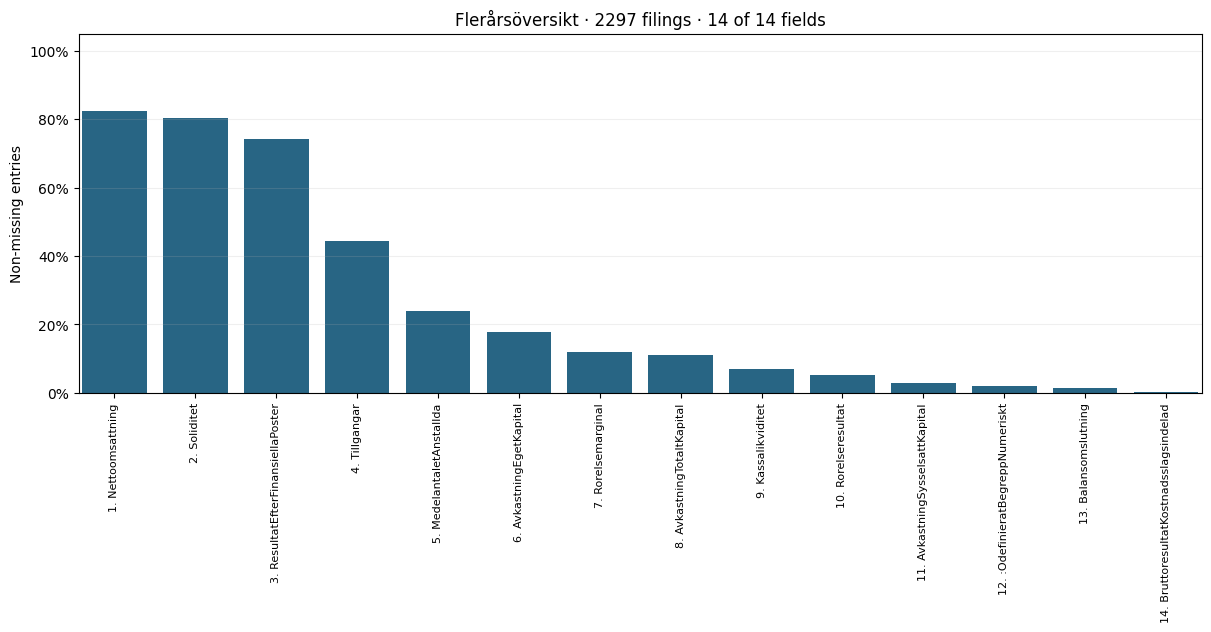

In [4]:
plot_coverage("Flerårsöversikt", overview_rows, limit=50, group_years=True)

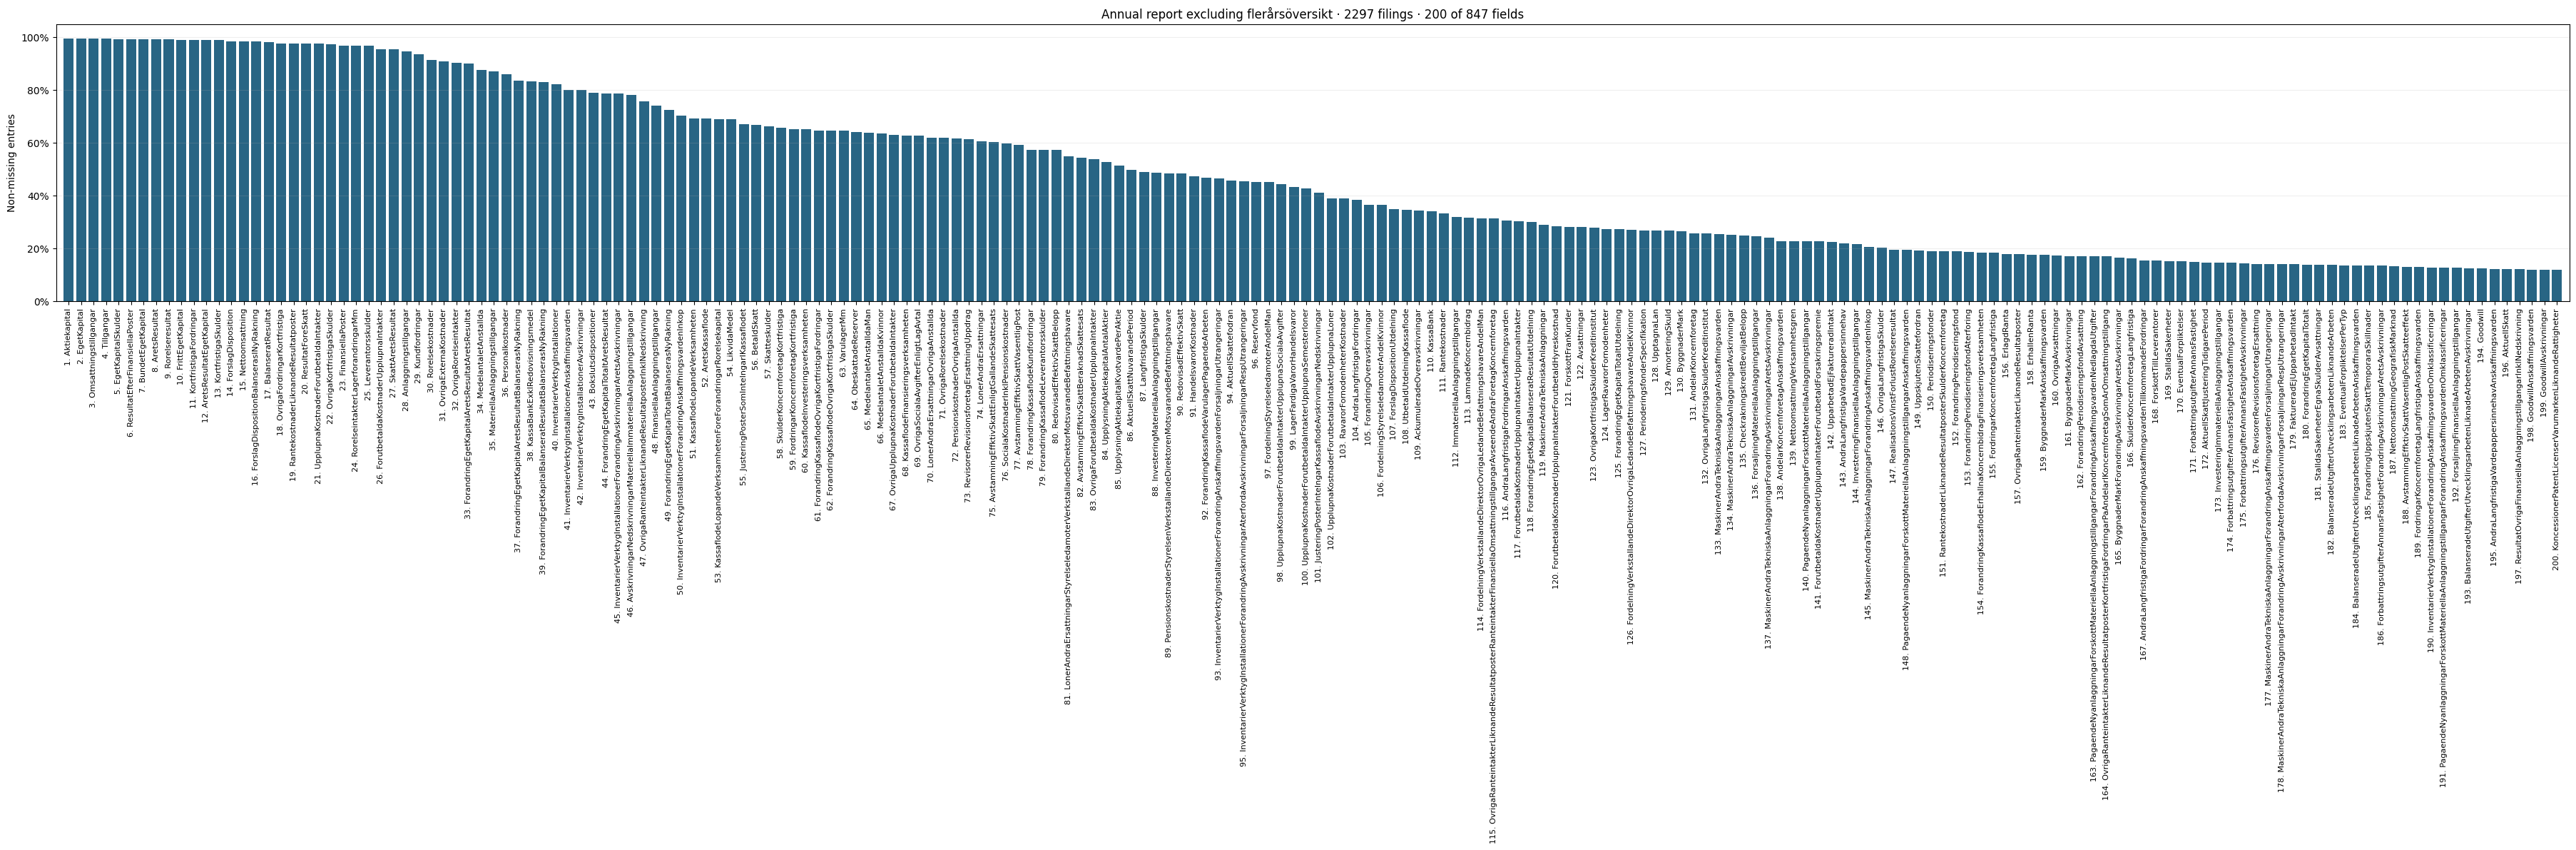

In [5]:
plot_coverage("Annual report excluding flerårsöversikt", other_rows, limit=200, group_years=True)

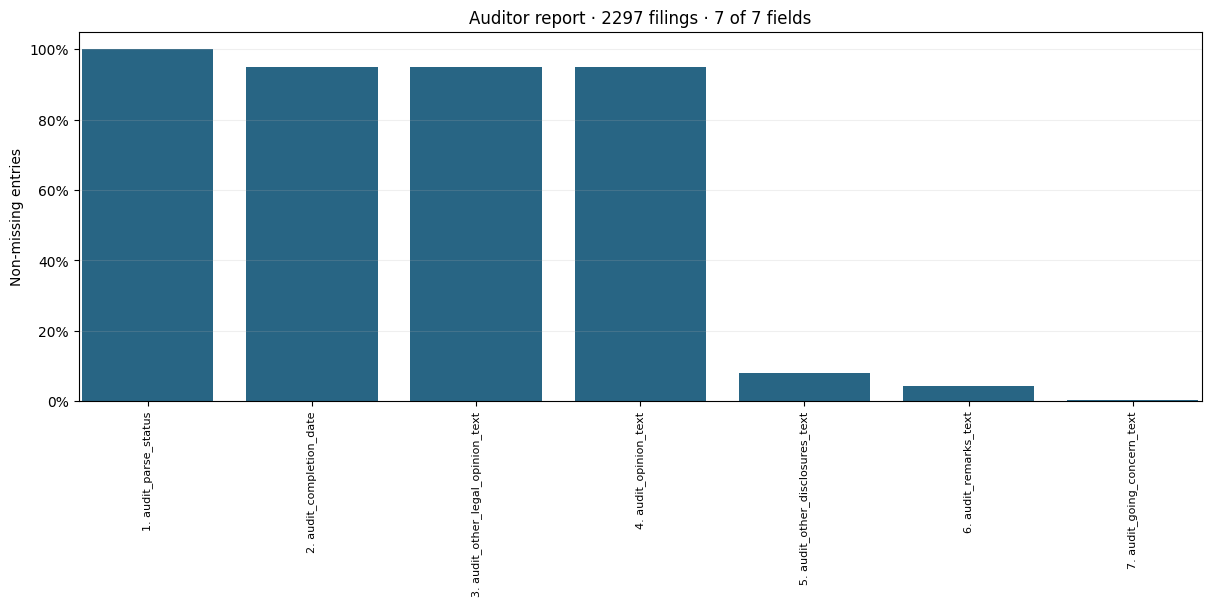

In [6]:
plot_coverage("Auditor report", audit_rows)

## Save a field selection
After running the plots, call `save_overview_fields(20)` or `save_other_report_fields(100)` with your chosen rank cutoff. Each call replaces its set in `src/config/selected_fields.py` and returns the selected column names. The ranking uses all years. Export keeps observed columns through index 3 and includes unindexed columns in selected groups.

In [9]:
import ast
from tempfile import NamedTemporaryFile

selection_path = project_root / "src/config/selected_fields.py"


def _save_ranked_fields(top_n, title, rows, setting):
    if type(top_n) is not int or top_n < 0:
        raise ValueError("top_n must be a nonnegative integer")

    groups = set(coverage[title].iloc[:top_n].index)
    fields = set()
    for column in {column for row in rows for column in row}:
        suffix = context_suffix.search(column)
        if suffix and int(suffix.group(1)) > 3:
            continue
        if context_suffix.sub("", column) in groups:
            fields.add(column)

    # Replace only this assignment so the other selection survives kernel restarts.
    source = selection_path.read_text(encoding="utf-8")
    assignment = next(node for node in ast.parse(source).body
                      if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Name)
                      and node.targets[0].id == setting)
    literal = "{\n" + "".join(f"    {name!r},\n" for name in sorted(fields)) + "}" if fields else "set()"
    lines = source.splitlines(keepends=True)
    lines[assignment.lineno - 1:assignment.end_lineno] = [f"{setting} = {literal}\n"]
    with NamedTemporaryFile(mode="w", encoding="utf-8", dir=selection_path.parent, delete=False) as tmp:
        tmp.writelines(lines)
    Path(tmp.name).replace(selection_path)
    return fields


def save_overview_fields(top_n):
    return _save_ranked_fields(top_n, "Flerårsöversikt", overview_rows, "OVERVIEW_FIELDS")


def save_other_report_fields(top_n):
    return _save_ranked_fields(top_n, "Annual report excluding flerårsöversikt",
                               other_rows, "OTHER_REPORT_FIELDS")

In [10]:
save_overview_fields(10)

{'AvkastningEgetKapital_PERIOD0',
 'AvkastningEgetKapital_PERIOD1',
 'AvkastningEgetKapital_PERIOD2',
 'AvkastningEgetKapital_PERIOD3',
 'AvkastningTotaltKapital_PERIOD0',
 'AvkastningTotaltKapital_PERIOD1',
 'AvkastningTotaltKapital_PERIOD2',
 'AvkastningTotaltKapital_PERIOD3',
 'Kassalikviditet_BALANS0',
 'Kassalikviditet_BALANS1',
 'Kassalikviditet_BALANS2',
 'Kassalikviditet_BALANS3',
 'MedelantaletAnstallda_PERIOD0',
 'MedelantaletAnstallda_PERIOD1',
 'MedelantaletAnstallda_PERIOD2',
 'MedelantaletAnstallda_PERIOD3',
 'Nettoomsattning_PERIOD0',
 'Nettoomsattning_PERIOD1',
 'Nettoomsattning_PERIOD2',
 'Nettoomsattning_PERIOD3',
 'ResultatEfterFinansiellaPoster_PERIOD0',
 'ResultatEfterFinansiellaPoster_PERIOD1',
 'ResultatEfterFinansiellaPoster_PERIOD2',
 'ResultatEfterFinansiellaPoster_PERIOD3',
 'Rorelsemarginal_PERIOD0',
 'Rorelsemarginal_PERIOD1',
 'Rorelsemarginal_PERIOD2',
 'Rorelsemarginal_PERIOD3',
 'Rorelseresultat_PERIOD0',
 'Rorelseresultat_PERIOD1',
 'Rorelseresultat_PE

In [11]:
save_other_report_fields(10)

{'Aktiekapital_BALANS0',
 'Aktiekapital_BALANS1',
 'AretsResultat_PERIOD0',
 'AretsResultat_PERIOD1',
 'EgetKapitalSkulder_BALANS0',
 'EgetKapitalSkulder_BALANS1',
 'EgetKapital_BALANS0',
 'EgetKapital_BALANS1',
 'ForslagDispositionBalanserasINyRakning_BALANS0',
 'FrittEgetKapital_BALANS0',
 'FrittEgetKapital_BALANS1',
 'Omsattningstillgangar_BALANS0',
 'Omsattningstillgangar_BALANS1',
 'ResultatEfterFinansiellaPoster_PERIOD0',
 'ResultatEfterFinansiellaPoster_PERIOD1',
 'Rorelseresultat_PERIOD0',
 'Rorelseresultat_PERIOD1',
 'Tillgangar_BALANS0',
 'Tillgangar_BALANS1'}